In [1]:
"""
STEP 6: GLOBAL NEURAL NETWORK MODEL
====================================

Single neural network that learns the ENTIRE velocity field U(x, z, U_ref, profile_type).

GLOBAL approach - one model for all spatial locations and conditions.

Author: Vit Uhlir
"""

from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR, REPORTS_DIR
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE);

In [2]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_11.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_21.pkl'
INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_51.pkl'

OUTPUT_DIR = FIGURES_DIR
RESULTS_OUTPUT = REPORTS_DIR / 'step6_global_results.pkl'

# Cube geometry
H_CUBE = 0.015  # meters
X_CUBE_FRONT = 0.075  # meters (x/H = 5.0)
X_CUBE_BACK = 0.090   # meters (x/H = 6.0)

In [3]:
# ============================================================================
# NETWORK CONFIGURATION
# ============================================================================

# Network architecture options
NETWORK_CONFIGS = {
    'small': {'hidden_sizes': [32, 16], 'name': 'Small (32-16)'},
    'medium': {'hidden_sizes': [64, 32], 'name': 'Medium (64-32)'},
    'large': {'hidden_sizes': [128, 64, 32], 'name': 'Large (128-64-32)'},
    'xlarge': {'hidden_sizes': [256, 128, 64], 'name': 'XLarge (256-128-64)'},
}

# Select configuration
NETWORK_SIZE = 'small'  # Options: 'small', 'medium', 'large', 'xlarge'

# Training parameters
LEARNING_RATE = 0.001
MAX_EPOCHS = 10000
PATIENCE = 1000  # Early stopping patience
MIN_DELTA = 1e-7
BATCH_SIZE = None  # None = full batch, or specify size

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

print("="*80)
print(" "*20 + "STEP 4: GLOBAL NEURAL NETWORK MODEL")
print("="*80)
print(f"\nNetwork configuration: {NETWORK_CONFIGS[NETWORK_SIZE]['name']}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Max epochs: {MAX_EPOCHS}")

                    STEP 4: GLOBAL NEURAL NETWORK MODEL

Network configuration: Small (32-16)
Learning rate: 0.001
Max epochs: 10000


In [4]:
# ============================================================================
# LOAD DATA
# ============================================================================

print(f"\n{'='*80}")
print("LOADING DATA")
print("="*80)

with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

print(f"✓ Loaded {len(all_cases_data)} cases")

# Extract case parameters
case_parameters = {}
for case_id, case_data in all_cases_data.items():
    case_parameters[case_id] = {
        'U_ref': case_data['U_ref'],
        'profile_type': case_data['profile_type'],
        'profile_name': case_data['profile_name'],
    }
    print(f"  {case_id}: {case_data['profile_name']}, U_ref={case_data['U_ref']}")



LOADING DATA
✓ Loaded 8 cases
  U1_uniform: Uniform, U_ref=1.0
  U1_ABL_const: ABL+constant, U_ref=1.0
  U1_ABL_lam: ABL+laminar, U_ref=1.0
  U1_ABL_free: ABL+free, U_ref=1.0
  U5_uniform: Uniform, U_ref=5.1
  U5_ABL_const: ABL+constant, U_ref=5.1
  U5_ABL_lam: ABL+laminar, U_ref=5.1
  U5_ABL_free: ABL+free, U_ref=5.1


In [5]:
# ============================================================================
# ONE-HOT ENCODING
# ============================================================================

print(f"\n{'='*80}")
print("ONE-HOT ENCODING")
print("="*80)

profile_types_all = np.array([[cp['profile_type']] for cp in case_parameters.values()])
onehot_encoder = OneHotEncoder(sparse_output=False, categories='auto')
onehot_encoder.fit(profile_types_all)

PROFILE_TYPE_MAP = {0: 'Uniform', 1: 'ABL+constant', 2: 'ABL+free', 3: 'ABL+laminar'}
N_PROFILE_TYPES = 4

print(f"✓ Profile type encoder fitted")

# Feature names for global model
FEATURE_NAMES = ['x_norm', 'z_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']
N_FEATURES = len(FEATURE_NAMES)

print(f"✓ Features: {FEATURE_NAMES}")



ONE-HOT ENCODING
✓ Profile type encoder fitted
✓ Features: ['x_norm', 'z_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']


In [6]:
# ============================================================================
# AUTOMATIC TRAIN/TEST SPLIT (Proportional by Flow Regime)
# ============================================================================

print(f"\n{'='*80}")
print("TRAIN/TEST SPLIT BY FLOW REGIME")
print("="*80)

all_x_locations = sorted(list(set([x for case_data in all_cases_data.values() 
                                     for x in case_data['profiles'].keys()])))

print(f"\nAvailable x-locations: {len(all_x_locations)}")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in all_x_locations]}")

# Categorize by flow regime
X_RECOVERY = 0.14

regime_locations = {
    'upstream': [],
    'over_cube': [],
    'wake': [],
    'far_downstream': []
}

for x in all_x_locations:
    if x < X_CUBE_FRONT:
        regime_locations['upstream'].append(x)
    elif x <= X_CUBE_BACK:
        regime_locations['over_cube'].append(x)
    elif x < X_RECOVERY:
        regime_locations['wake'].append(x)
    else:
        regime_locations['far_downstream'].append(x)

print(f"\n📍 Locations by flow regime:")
for regime, locs in regime_locations.items():
    x_H = [f'{x/H_CUBE:.1f}' for x in locs]
    print(f"  {regime:15s}: {len(locs):2d} locations  (x/H: {x_H})")


# TEST SELECTION STRATEGY
# Option 1: Fixed 1 per regime (current)
# Option 2: Proportional (~20% from each regime)
# Option 3: Fixed total percentage

TEST_STRATEGY = 'proportional'  # Options: 'one_per_regime', 'proportional', 'percentage'
TEST_FRACTION = 0.2  # For 'proportional' and 'percentage' strategies

x_test = []
test_selection = {}

if TEST_STRATEGY == 'one_per_regime':
    # Original: 1 test location per regime (always 4 total)
    for regime, locs in regime_locations.items():
        if len(locs) >= 2:
            mid_idx = len(locs) // 2
            x_test.append(locs[mid_idx])
            test_selection[regime] = [locs[mid_idx]]
        elif len(locs) == 1:
            test_selection[regime] = []
            print(f"  ⚠️  {regime}: Only 1 location, keeping for training")
        else:
            test_selection[regime] = []

elif TEST_STRATEGY == 'proportional':
    # Proportional: ~20% from each regime, minimum 1 if regime has ≥3 points
    for regime, locs in regime_locations.items():
        n_locs = len(locs)
        if n_locs >= 3:
            # Take ~20% but at least 1
            n_test = max(1, int(n_locs * TEST_FRACTION))
            # Select evenly spaced indices (not edges)
            if n_test == 1:
                indices = [n_locs // 2]
            else:
                # Avoid first and last, distribute evenly
                indices = np.linspace(1, n_locs - 2, n_test, dtype=int)
            selected = [locs[i] for i in indices]
            x_test.extend(selected)
            test_selection[regime] = selected
        elif n_locs == 2:
            # Take middle-ish (index 1)
            x_test.append(locs[1])
            test_selection[regime] = [locs[1]]
        elif n_locs == 1:
            test_selection[regime] = []
            print(f"  ⚠️  {regime}: Only 1 location, keeping for training")
        else:
            test_selection[regime] = []

elif TEST_STRATEGY == 'percentage':
    # Simple percentage of total, distributed across regimes
    n_total_test = max(4, int(len(all_x_locations) * TEST_FRACTION))
    # Distribute proportionally to regime size
    total_locs = sum(len(locs) for locs in regime_locations.values())
    
    for regime, locs in regime_locations.items():
        n_locs = len(locs)
        if n_locs >= 2:
            # Proportion of test points for this regime
            n_test = max(1, int(n_total_test * n_locs / total_locs))
            # Select from middle
            if n_test == 1:
                indices = [n_locs // 2]
            else:
                indices = np.linspace(1, n_locs - 2, n_test, dtype=int)
            selected = [locs[i] for i in indices]
            x_test.extend(selected)
            test_selection[regime] = selected
        else:
            test_selection[regime] = []

x_train = [x for x in all_x_locations if x not in x_test]
x_train = sorted(x_train)
x_test = sorted(x_test)


# SUMMARY
print(f"\n{'─'*60}")
print(f"TEST STRATEGY: {TEST_STRATEGY}")
print(f"{'─'*60}")

print(f"\n✓ Test locations by regime:")
for regime, locs in test_selection.items():
    if locs:
        x_H = [f'{x/H_CUBE:.1f}' for x in locs]
        print(f"  {regime:15s}: {len(locs):2d} test  (x/H: {x_H})")
    else:
        print(f"  {regime:15s}:  0 test")

print(f"\n✓ Training: {len(x_train)} x-locations ({100*len(x_train)/len(all_x_locations):.0f}%)")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_train]}")

print(f"\n✓ Testing: {len(x_test)} x-locations ({100*len(x_test)/len(all_x_locations):.0f}%)")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_test]}")


TRAIN/TEST SPLIT BY FLOW REGIME

Available x-locations: 25
  x/H: ['0.0', '0.9', '1.8', '2.6', '3.5', '4.4', '5.2', '6.1', '7.0', '7.9', '8.8', '9.6', '10.5', '11.4', '12.2', '13.1', '14.0', '14.9', '15.8', '16.6', '17.5', '18.4', '19.2', '20.1', '21.0']

📍 Locations by flow regime:
  upstream       :  6 locations  (x/H: ['0.0', '0.9', '1.8', '2.6', '3.5', '4.4'])
  over_cube      :  1 locations  (x/H: ['5.2'])
  wake           :  4 locations  (x/H: ['6.1', '7.0', '7.9', '8.8'])
  far_downstream : 14 locations  (x/H: ['9.6', '10.5', '11.4', '12.2', '13.1', '14.0', '14.9', '15.8', '16.6', '17.5', '18.4', '19.2', '20.1', '21.0'])
  ⚠️  over_cube: Only 1 location, keeping for training

────────────────────────────────────────────────────────────
TEST STRATEGY: proportional
────────────────────────────────────────────────────────────

✓ Test locations by regime:
  upstream       :  1 test  (x/H: ['2.6'])
  over_cube      :  0 test
  wake           :  1 test  (x/H: ['7.9'])
  far_downstrea

In [7]:
# ============================================================================
# PREPARE TRAINING AND TEST DATA
# ============================================================================

print(f"\n{'='*80}")
print("PREPARING TRAINING AND TEST DATA")
print("="*80)

def extract_data_points(cases_data, case_params, x_locations, onehot_enc, H_cube):
    """Extract all data points for given x-locations."""
    points = []
    
    for case_id, case_data in cases_data.items():
        params = case_params[case_id]
        
        for x_loc in x_locations:
            if x_loc in case_data['profiles']:
                profile = case_data['profiles'][x_loc]
                z_vals = profile['z']
                U_vals = profile['U_x']
                
                for z_val, U_val in zip(z_vals, U_vals):
                    x_norm = x_loc / H_cube
                    z_norm = z_val / H_cube
                    profile_onehot = onehot_enc.transform([[params['profile_type']]])[0]
                    
                    features = np.concatenate([[x_norm, z_norm, params['U_ref']], profile_onehot])
                    
                    points.append({
                        'x': x_loc,
                        'z': z_val,
                        'x_norm': x_norm,
                        'z_norm': z_norm,
                        'U_ref': params['U_ref'],
                        'profile_type': params['profile_type'],
                        'case_id': case_id,
                        'features': features,
                        'U_x': U_val
                    })
    
    return points

# Extract training data
train_points = extract_data_points(all_cases_data, case_parameters, x_train, onehot_encoder, H_CUBE)
X_train = np.array([p['features'] for p in train_points])
y_train = np.array([p['U_x'] for p in train_points])

# Extract test data
test_points = extract_data_points(all_cases_data, case_parameters, x_test, onehot_encoder, H_CUBE)
X_test = np.array([p['features'] for p in test_points])
y_test = np.array([p['U_x'] for p in test_points])

print(f"✓ Training data: {len(train_points)} points")
print(f"  X_train shape: {X_train.shape}")
print(f"  y_train shape: {y_train.shape}")

print(f"\n✓ Test data: {len(test_points)} points")
print(f"  X_test shape: {X_test.shape}")
print(f"  y_test shape: {y_test.shape}")

# Feature scaling
feature_scaler = StandardScaler()
X_train_scaled = feature_scaler.fit_transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)

print(f"\n✓ Feature scaler fitted")
print(f"  Means: {feature_scaler.mean_}")
print(f"  Stds:  {feature_scaler.scale_}")

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)



PREPARING TRAINING AND TEST DATA
✓ Training data: 9240 points
  X_train shape: (9240, 7)
  y_train shape: (9240,)

✓ Test data: 1760 points
  X_test shape: (1760, 7)
  y_test shape: (1760,)

✓ Feature scaler fitted
  Means: [10.54318182  1.36961467  3.05        0.25        0.25        0.25
  0.25      ]
  Stds:  [6.30047278 0.9174872  2.05       0.4330127  0.4330127  0.4330127
 0.4330127 ]


In [8]:
# ============================================================================
# NEURAL NETWORK DEFINITION
# ============================================================================

print(f"\n{'='*80}")
print("DEFINING NEURAL NETWORK")
print("="*80)

class GlobalFlowNet(nn.Module):
    """
    Global neural network for velocity field prediction.
    Input: [x_norm, z_norm, U_ref, profile_type_onehot]
    Output: U_x velocity
    """
    def __init__(self, n_inputs, hidden_sizes, activation='tanh'):
        super().__init__()
        
        layers = []
        prev_size = n_inputs
        
        # Hidden layers
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(prev_size, hidden_size))
            if activation == 'tanh':
                layers.append(nn.Tanh())
            elif activation == 'relu':
                layers.append(nn.ReLU())
            elif activation == 'leaky_relu':
                layers.append(nn.LeakyReLU(0.1))
            prev_size = hidden_size
        
        # Output layer
        layers.append(nn.Linear(prev_size, 1))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)


# Create model
hidden_sizes = NETWORK_CONFIGS[NETWORK_SIZE]['hidden_sizes']
model = GlobalFlowNet(n_inputs=N_FEATURES, hidden_sizes=hidden_sizes, activation='tanh')

n_params = sum(p.numel() for p in model.parameters())
print(f"\n✓ Network created: {NETWORK_CONFIGS[NETWORK_SIZE]['name']}")
print(f"  Architecture: {N_FEATURES} → {' → '.join(map(str, hidden_sizes))} → 1")
print(f"  Total parameters: {n_params}")
print(f"  Training samples: {len(X_train)}")
print(f"  Params/samples ratio: {n_params/len(X_train):.2f}")



DEFINING NEURAL NETWORK

✓ Network created: Small (32-16)
  Architecture: 7 → 32 → 16 → 1
  Total parameters: 801
  Training samples: 9240
  Params/samples ratio: 0.09



TRAINING GLOBAL NETWORK

Running ALL optimizers for comparison: ['Adam', 'L-BFGS', 'SGD', 'RMSprop']

OPTIMIZER: Adam

Training with Adam for up to 10000 epochs...
   Epoch   Train Loss    Test Loss           LR
--------------------------------------------------
       0     9.207757     8.093195     0.010000
    1000     0.056134     0.041238     0.010000
    2000     0.020789     0.030450     0.010000
    3000     0.012266     0.034027     0.010000
    4000     0.008541     0.037248     0.010000
    5000     0.006452     0.051185     0.010000
    6000     0.005340     0.074316     0.010000
    7000     0.005933     0.092251     0.010000
    8000     0.003686     0.095862     0.010000
    9000     0.003276     0.094763     0.010000
    9999     0.003163     0.092032     0.010000

Final training loss: 0.003163
Best training loss: 0.002911

📊 Adam Results:
  Training time: 68.13s
  Iterations/Epochs: 10000
  Train R²: 0.9992, RMSE: 0.0568, MAE: 0.0364
  Test R²:  0.9796, RMSE: 0.3034, 

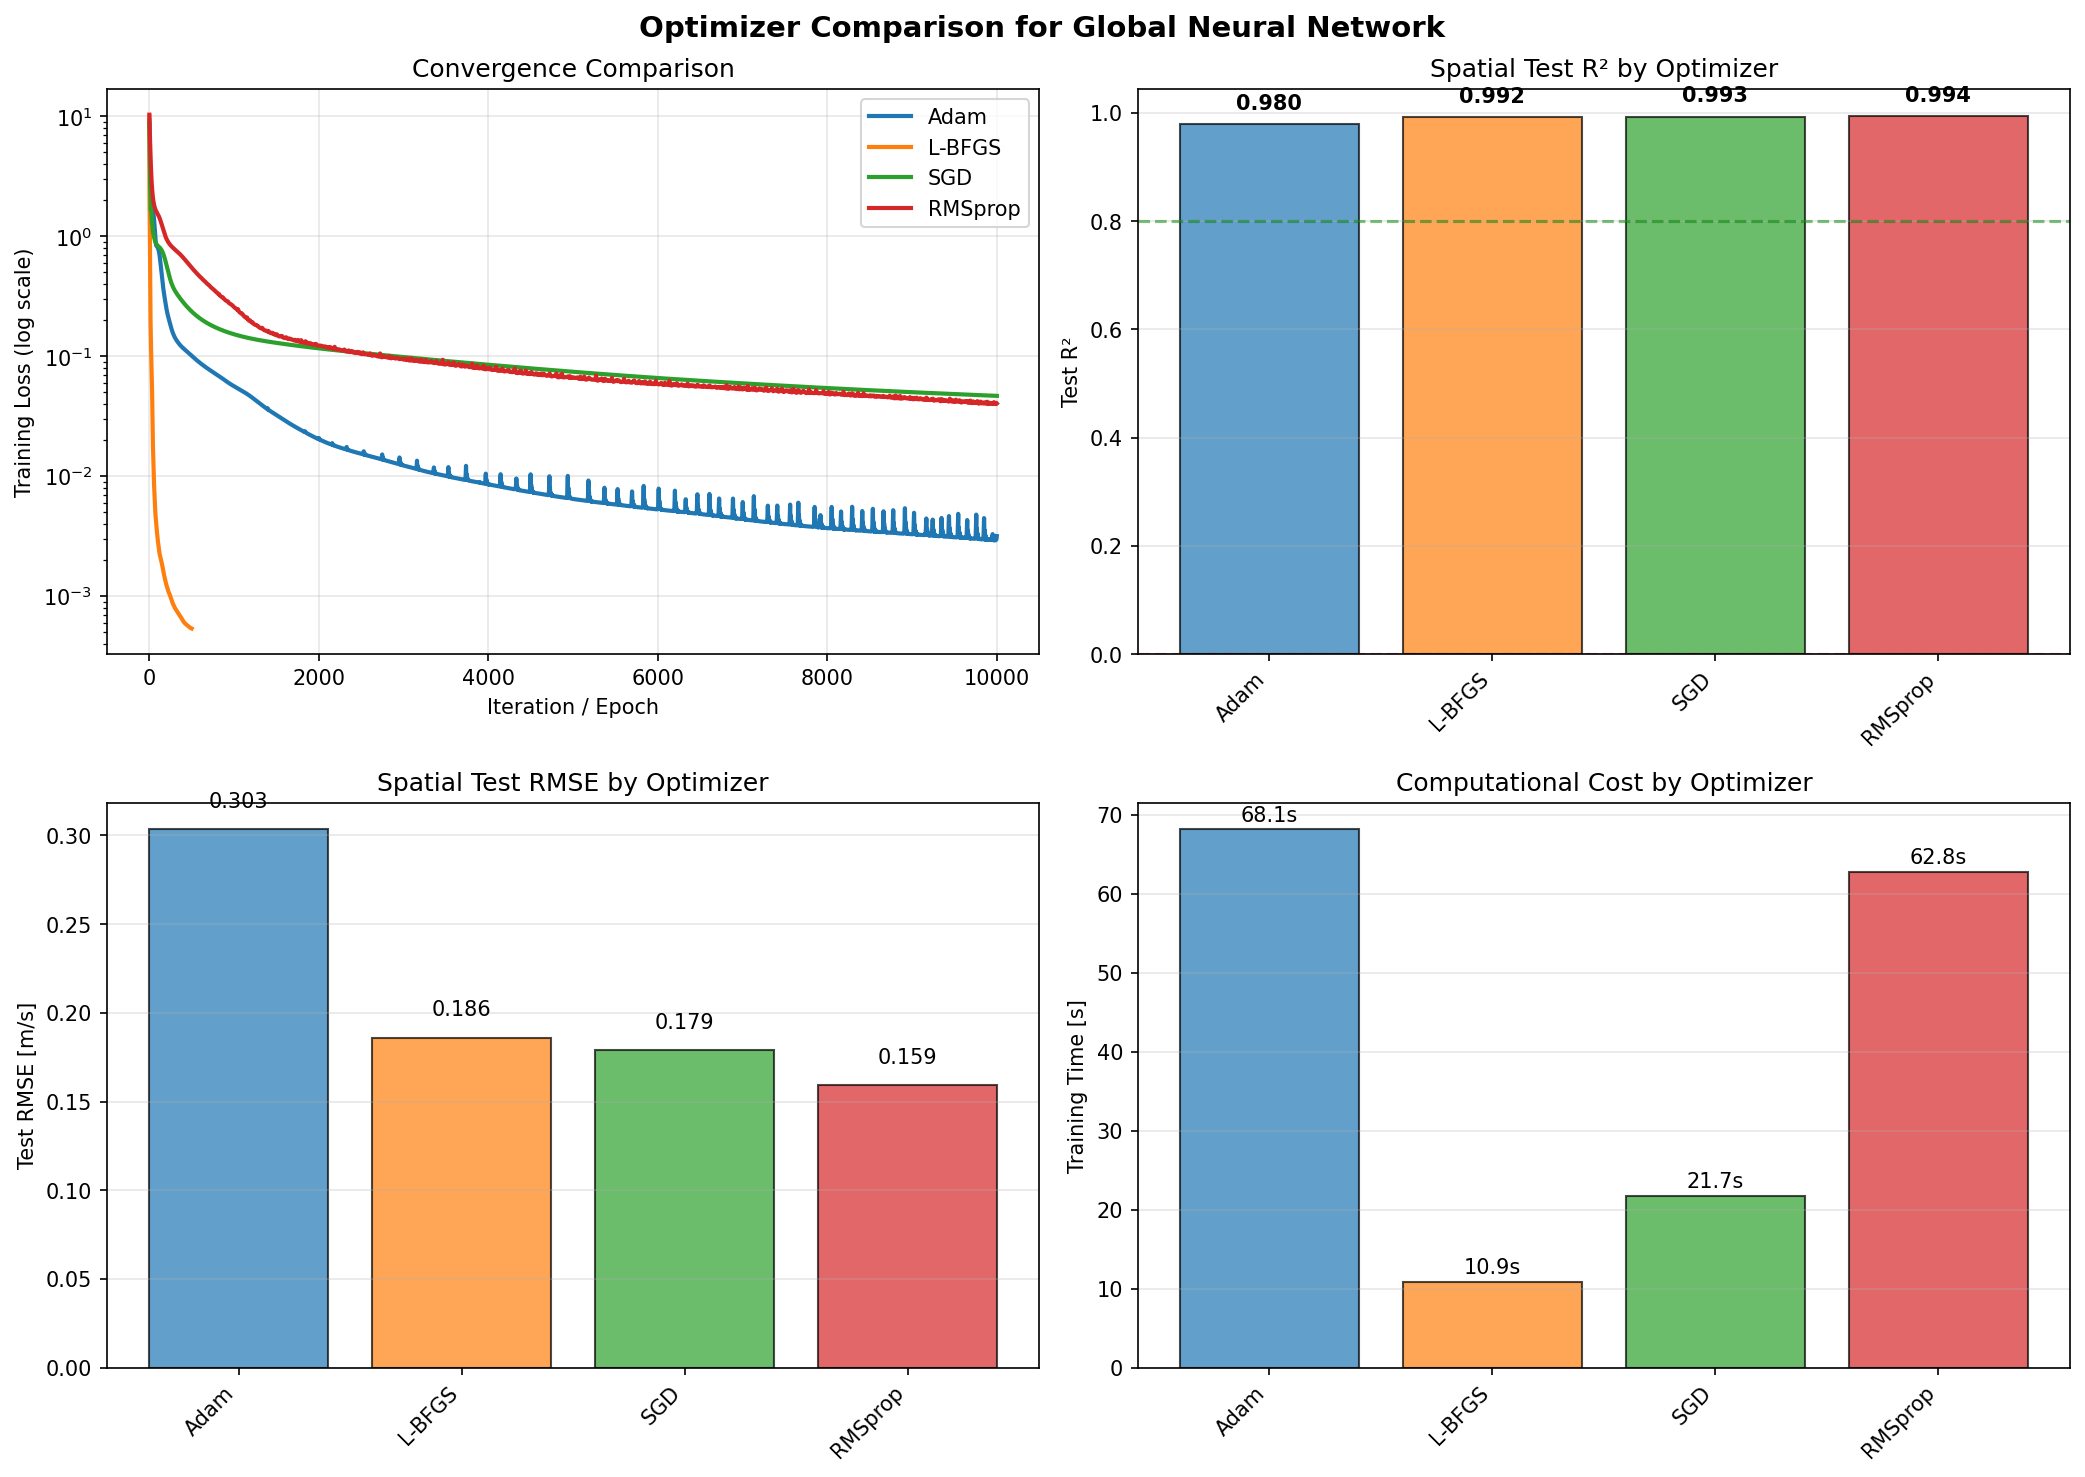


✓ Saved: step6_0_optimizer_comparison.png

FINAL MODEL: RMSprop
  Train R²:  0.9901
  Train RMSE: 0.2009
  Test R²:   0.9944
  Test RMSE: 0.1591


In [9]:
# ============================================================================
# TRAINING
# ============================================================================

# OPTIMIZER CONFIGURATION
# OPTIONS:
#   'Adam'                - Adaptive moment estimation (1st order, modern default)
#   'L-BFGS'              - Limited-memory BFGS (quasi-Newton, ~2nd order)
#   'SGD'                 - Stochastic gradient descent (1st order, classic)
#   'RMSprop'             - Root mean square propagation (1st order, adaptive)
#   'Levenberg-Marquardt' - Trust region (2nd order, classic for small networks)
#   'ALL'                 - Run all optimizers and compare

OPTIMIZER = 'ALL'  # Options: 'Adam', 'L-BFGS', 'SGD', 'RMSprop', 'Levenberg-Marquardt', 'ALL'

# Training parameters
PRINT_EVERY = 1000  # Print progress every N epochs


# HELPER FUNCTIONS FOR LEVENBERG-MARQUARDT
from scipy.optimize import least_squares
import time

def get_model_params(model):
    """Flatten all model parameters to 1D numpy array."""
    params = []
    for p in model.parameters():
        params.append(p.detach().cpu().numpy().flatten())
    return np.concatenate(params)

def set_model_params(model, params):
    """Set model parameters from 1D numpy array."""
    idx = 0
    for p in model.parameters():
        size = p.numel()
        new_data = torch.tensor(
            params[idx:idx+size].reshape(p.shape), 
            dtype=torch.float32
        )
        p.data = new_data
        idx += size

def lm_residuals(params, model, X, y):
    """Compute residuals for Levenberg-Marquardt."""
    set_model_params(model, params)
    with torch.no_grad():
        y_pred = model(X).numpy().flatten()
    return y_pred - y.flatten()

# TRAINING FUNCTION FOR PYTORCH OPTIMIZERS
def train_pytorch_optimizer(model, X_train, y_train, X_test, y_test,
                            optimizer_name, optimizer_class, optimizer_params,
                            max_epochs, use_scheduler=True, print_every=1000):
    """
    Train model with PyTorch optimizer (Adam, L-BFGS, SGD, RMSprop).
    """
    print(f"\nTraining with {optimizer_name} for up to {max_epochs} epochs...")
    print(f"{'Epoch':>8s} {'Train Loss':>12s} {'Test Loss':>12s} {'LR':>12s}")
    print("-" * 50)
    
    # Setup optimizer
    optimizer = optimizer_class(model.parameters(), **optimizer_params)
    
    # Setup scheduler
    if use_scheduler and optimizer_name != 'L-BFGS':
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=0.5, patience=500, min_lr=1e-6
        )
    else:
        scheduler = None
    
    criterion = nn.MSELoss()
    
    # Training tracking
    losses = []
    val_losses = []
    learning_rates = []
    best_loss = float('inf')
    best_model_state = None
    patience_counter = 0
    
    # Closure for L-BFGS
    def closure():
        optimizer.zero_grad()
        y_pred = model(X_train)
        loss = criterion(y_pred, y_train)
        loss.backward()
        return loss
    
    is_lbfgs = (optimizer_name == 'L-BFGS')
    
    # Training loop
    for epoch in range(max_epochs):
        model.train()
        
        if is_lbfgs:
            loss = optimizer.step(closure)
        else:
            optimizer.zero_grad()
            y_pred_train = model(X_train)
            loss = criterion(y_pred_train, y_train)
            loss.backward()
            optimizer.step()
        
        # Validation
        model.eval()
        with torch.no_grad():
            y_pred_test = model(X_test)
            val_loss = criterion(y_pred_test, y_test)
        
        # Record
        current_loss = loss.item() if isinstance(loss, torch.Tensor) else loss
        losses.append(current_loss)
        val_losses.append(val_loss.item())
        current_lr = optimizer.param_groups[0]['lr']
        learning_rates.append(current_lr)
        
        # Scheduler step
        if scheduler is not None:
            scheduler.step(current_loss)
        
        # Early stopping check
        if best_loss - current_loss > MIN_DELTA:
            best_loss = current_loss
            best_model_state = model.state_dict().copy()
            patience_counter = 0
        else:
            patience_counter += 1
        
        # Print progress
        if epoch % print_every == 0 or epoch == max_epochs - 1:
            print(f"{epoch:>8d} {current_loss:>12.6f} {val_loss.item():>12.6f} {current_lr:>12.6f}")
        
        # Convergence check
        if current_loss < 1e-6:
            print(f"\n✓ Converged at epoch {epoch}")
            break
        
        # Early stopping
        if patience_counter >= PATIENCE:
            print(f"\n✓ Early stopping at epoch {epoch}")
            break
    
    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    print(f"\nFinal training loss: {losses[-1]:.6f}")
    print(f"Best training loss: {best_loss:.6f}")
    
    return {
        'losses': losses,
        'val_losses': val_losses,
        'learning_rates': learning_rates,
        'best_loss': best_loss,
        'epochs': len(losses),
        'model_state': best_model_state
    }


# TRAINING FUNCTION FOR LEVENBERG-MARQUARDT
def train_levenberg_marquardt(model, X_train, y_train, X_test, y_test, 
                               max_nfev=5000, print_every=100):
    """
    Train neural network using Levenberg-Marquardt algorithm.
    """
    print(f"\nTraining with Levenberg-Marquardt...")
    print(f"{'Iteration':>10s} {'Cost':>15s} {'Status':>15s}")
    print("-" * 45)
    
    criterion = nn.MSELoss()
    params0 = get_model_params(model)
    n_params = len(params0)
    
    print(f"  Parameters to optimize: {n_params}")
    
    # Track iterations
    iteration_count = [0]
    losses = []
    
    def callback_residuals(params):
        """Residuals function with progress printing."""
        set_model_params(model, params)
        with torch.no_grad():
            y_pred = model(X_train).numpy().flatten()
        residuals = y_pred - y_train.numpy().flatten()
        
        # Track progress
        iteration_count[0] += 1
        cost = np.sum(residuals**2)
        losses.append(cost / len(residuals))  # MSE
        
        if iteration_count[0] % print_every == 0:
            print(f"{iteration_count[0]:>10d} {cost:>15.6f} {'Running...':>15s}")
        
        return residuals
    
    # Initial cost
    initial_residuals = callback_residuals(params0)
    initial_cost = np.sum(initial_residuals**2)
    print(f"{'0':>10s} {initial_cost:>15.6f} {'Initial':>15s}")
    
    # Run Levenberg-Marquardt
    result = least_squares(
        callback_residuals,
        params0,
        method='lm',
        ftol=1e-8,
        xtol=1e-8,
        gtol=1e-8,
        max_nfev=max_nfev,
        verbose=0
    )
    
    # Set final parameters
    set_model_params(model, result.x)
    
    # Final evaluation
    with torch.no_grad():
        final_train_loss = criterion(model(X_train), y_train).item()
        final_val_loss = criterion(model(X_test), y_test).item()
    
    print(f"\n{'Final':>10s} {result.cost:>15.6f} {result.message:>15s}")
    print(f"\nFunction evaluations: {result.nfev}")
    print(f"Final training loss (MSE): {final_train_loss:.6f}")
    print(f"Final validation loss (MSE): {final_val_loss:.6f}")
    
    return {
        'losses': losses,
        'val_losses': [final_val_loss],
        'learning_rates': [1.0],
        'best_loss': final_train_loss,
        'epochs': result.nfev,
        'model_state': model.state_dict().copy(),
        'scipy_result': result
    }

# OPTIMIZER CONFIGURATIONS
OPTIMIZER_CONFIGS = {
    'Adam': {
        'class': torch.optim.Adam,
        'params': {'lr': 0.01},
        'max_epochs': MAX_EPOCHS,
        'use_scheduler': True,
        'train_func': 'pytorch'
    },
    'L-BFGS': {
        'class': torch.optim.LBFGS,
        'params': {'lr': 0.01, 'max_iter': 20, 'history_size': 50},
        'max_epochs': 500,
        'use_scheduler': False,
        'train_func': 'pytorch'
    },
    'SGD': {
        'class': torch.optim.SGD,
        'params': {'lr': 0.01, 'momentum': 0.9},
        'max_epochs': MAX_EPOCHS,
        'use_scheduler': True,
        'train_func': 'pytorch'
    },
    'RMSprop': {
        'class': torch.optim.RMSprop,
        'params': {'lr': 0.001},
        'max_epochs': MAX_EPOCHS,
        'use_scheduler': True,
        'train_func': 'pytorch'
    },
#     'Levenberg-Marquardt': {
#         'max_nfev': 5000,
#         'train_func': 'lm'
#     }
}


# TRAINING
print(f"\n{'='*80}")
print("TRAINING GLOBAL NETWORK")
print("="*80)

# Determine which optimizers to run
if OPTIMIZER == 'ALL':
    optimizers_to_run = list(OPTIMIZER_CONFIGS.keys())
    print(f"\nRunning ALL optimizers for comparison: {optimizers_to_run}")
else:
    optimizers_to_run = [OPTIMIZER]
    print(f"\nUsing optimizer: {OPTIMIZER}")

# Storage for results
optimizer_results = {}

# Train with each optimizer
for opt_name in optimizers_to_run:
    print(f"\n{'='*80}")
    print(f"OPTIMIZER: {opt_name}")
    print(f"{'='*80}")
    
    config = OPTIMIZER_CONFIGS[opt_name]
    
    # Create fresh model for each optimizer
    model = GlobalFlowNet(n_inputs=N_FEATURES, hidden_sizes=hidden_sizes, activation='tanh')
    
    # Train
    start_time = time.time()
    
    if config['train_func'] == 'pytorch':
        history = train_pytorch_optimizer(
            model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
            optimizer_name=opt_name,
            optimizer_class=config['class'],
            optimizer_params=config['params'],
            max_epochs=config['max_epochs'],
            use_scheduler=config['use_scheduler'],
            print_every=PRINT_EVERY
        )
    elif config['train_func'] == 'lm':
        history = train_levenberg_marquardt(
            model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
            max_nfev=config['max_nfev'],
            print_every=100
        )
    
    training_time = time.time() - start_time
    
    # Evaluate final model
    model.eval()
    with torch.no_grad():
        y_pred_train = model(X_train_tensor).numpy().flatten()
        y_pred_test = model(X_test_tensor).numpy().flatten()
    
    train_R2 = r2_score(y_train, y_pred_train)
    train_RMSE = np.sqrt(mean_squared_error(y_train, y_pred_train))
    train_MAE = mean_absolute_error(y_train, y_pred_train)
    test_R2 = r2_score(y_test, y_pred_test)
    test_RMSE = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_MAE = mean_absolute_error(y_test, y_pred_test)
    
    # Store results
    optimizer_results[opt_name] = {
        'history': history,
        'train_R2': train_R2,
        'train_RMSE': train_RMSE,
        'train_MAE': train_MAE,
        'test_R2': test_R2,
        'test_RMSE': test_RMSE,
        'test_MAE': test_MAE,
        'training_time': training_time,
        'epochs': history['epochs'],
        'model_state': history['model_state']
    }
    
    print(f"\n📊 {opt_name} Results:")
    print(f"  Training time: {training_time:.2f}s")
    print(f"  Iterations/Epochs: {history['epochs']}")
    print(f"  Train R²: {train_R2:.4f}, RMSE: {train_RMSE:.4f}, MAE: {train_MAE:.4f}")
    print(f"  Test R²:  {test_R2:.4f}, RMSE: {test_RMSE:.4f}, MAE: {test_MAE:.4f}")

# OPTIMIZER COMPARISON SUMMARY (if ALL)
if OPTIMIZER == 'ALL':
    print(f"\n{'='*80}")
    print("OPTIMIZER COMPARISON SUMMARY")
    print("="*80)
    
    print(f"\n{'Optimizer':<22s} {'Epochs':>8s} {'Time':>8s} {'Train R²':>10s} {'Test R²':>10s} {'Test RMSE':>12s}")
    print("-" * 78)
    
    for opt_name in optimizers_to_run:
        r = optimizer_results[opt_name]
        print(f"{opt_name:<22s} {r['epochs']:>8d} {r['training_time']:>7.1f}s "
              f"{r['train_R2']:>10.4f} {r['test_R2']:>10.4f} {r['test_RMSE']:>12.4f}")
    
    # Find best optimizer
    best_opt_r2 = max(optimizers_to_run, key=lambda x: optimizer_results[x]['test_R2'])
    best_opt_rmse = min(optimizers_to_run, key=lambda x: optimizer_results[x]['test_RMSE'])
    best_opt_time = min(optimizers_to_run, key=lambda x: optimizer_results[x]['training_time'])
    
    print("-" * 78)
    print(f"\n✓ Best Test R²:   {best_opt_r2} ({optimizer_results[best_opt_r2]['test_R2']:.4f})")
    print(f"✓ Best Test RMSE: {best_opt_rmse} ({optimizer_results[best_opt_rmse]['test_RMSE']:.4f})")
    print(f"✓ Fastest:        {best_opt_time} ({optimizer_results[best_opt_time]['training_time']:.1f}s)")
    
    # Use best model (by Test R²) for subsequent analysis
    best_opt = best_opt_r2
    print(f"\n→ Using {best_opt} for subsequent analysis")
    

    # VISUALIZATION: OPTIMIZER COMPARISON
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    colors = {
        'Adam': 'tab:blue',
        'L-BFGS': 'tab:orange', 
        'SGD': 'tab:green',
        'RMSprop': 'tab:red',
        'Levenberg-Marquardt': 'tab:purple'
    }
    
    # Plot 1: Training loss curves
    ax = axes[0, 0]
    for opt_name in optimizers_to_run:
        losses = optimizer_results[opt_name]['history']['losses']
        ax.semilogy(losses, label=opt_name, color=colors.get(opt_name, 'gray'), linewidth=2)
    ax.set_xlabel('Iteration / Epoch')
    ax.set_ylabel('Training Loss (log scale)')
    ax.set_title('Convergence Comparison')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Plot 2: Test R² comparison
    ax = axes[0, 1]
    opt_names = list(optimizer_results.keys())
    test_r2_vals = [optimizer_results[opt]['test_R2'] for opt in opt_names]
    bar_colors = [colors.get(opt, 'gray') for opt in opt_names]
    bars = ax.bar(range(len(opt_names)), test_r2_vals, color=bar_colors, alpha=0.7, edgecolor='black')
    ax.set_xticks(range(len(opt_names)))
    ax.set_xticklabels(opt_names, rotation=45, ha='right')
    ax.set_ylabel('Test R²')
    ax.set_title('Spatial Test R² by Optimizer')
    ax.axhline(0, color='red', linestyle='--', alpha=0.5)
    ax.axhline(0.8, color='green', linestyle='--', alpha=0.5)
    for bar, val in zip(bars, test_r2_vals):
        ax.text(bar.get_x() + bar.get_width()/2, max(val, 0) + 0.02, f'{val:.3f}', 
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')
    
    # Plot 3: Test RMSE comparison
    ax = axes[1, 0]
    test_rmse_vals = [optimizer_results[opt]['test_RMSE'] for opt in opt_names]
    bars = ax.bar(range(len(opt_names)), test_rmse_vals, color=bar_colors, alpha=0.7, edgecolor='black')
    ax.set_xticks(range(len(opt_names)))
    ax.set_xticklabels(opt_names, rotation=45, ha='right')
    ax.set_ylabel('Test RMSE [m/s]')
    ax.set_title('Spatial Test RMSE by Optimizer')
    for bar, val in zip(bars, test_rmse_vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', 
                ha='center', va='bottom', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Plot 4: Training time comparison
    ax = axes[1, 1]
    times = [optimizer_results[opt]['training_time'] for opt in opt_names]
    bars = ax.bar(range(len(opt_names)), times, color=bar_colors, alpha=0.7, edgecolor='black')
    ax.set_xticks(range(len(opt_names)))
    ax.set_xticklabels(opt_names, rotation=45, ha='right')
    ax.set_ylabel('Training Time [s]')
    ax.set_title('Computational Cost by Optimizer')
    for bar, val in zip(bars, times):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.5, f'{val:.1f}s', 
                ha='center', va='bottom', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.suptitle('Optimizer Comparison for Global Neural Network', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'step6_0_optimizer_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("\n✓ Saved: step6_0_optimizer_comparison.png")
    plt.close()

else:
    # Single optimizer - use it directly
    best_opt = OPTIMIZER

# SET FINAL MODEL (Best optimizer)
# Load the best model for subsequent analysis
model = GlobalFlowNet(n_inputs=N_FEATURES, hidden_sizes=hidden_sizes, activation='tanh')
model.load_state_dict(optimizer_results[best_opt]['model_state'])

# Store metrics for later use
train_R2 = optimizer_results[best_opt]['train_R2']
train_RMSE = optimizer_results[best_opt]['train_RMSE']
train_MAE = optimizer_results[best_opt]['train_MAE']
losses = optimizer_results[best_opt]['history']['losses']
val_losses = optimizer_results[best_opt]['history']['val_losses']
learning_rates = optimizer_results[best_opt]['history']['learning_rates']

print(f"\n{'='*80}")
print(f"FINAL MODEL: {best_opt}")
print(f"{'='*80}")
print(f"  Train R²:  {train_R2:.4f}")
print(f"  Train RMSE: {train_RMSE:.4f}")
print(f"  Test R²:   {optimizer_results[best_opt]['test_R2']:.4f}")
print(f"  Test RMSE: {optimizer_results[best_opt]['test_RMSE']:.4f}")


In [10]:
# ============================================================================
# EVALUATION
# ============================================================================

print(f"\n{'='*80}")
print("EVALUATION")
print("="*80)

model.eval()

# Training metrics
with torch.no_grad():
    y_pred_train = model(X_train_tensor).numpy().flatten()
    y_pred_test = model(X_test_tensor).numpy().flatten()

# Overall training metrics
train_R2 = r2_score(y_train, y_pred_train)
train_RMSE = np.sqrt(mean_squared_error(y_train, y_pred_train))
train_MAE = mean_absolute_error(y_train, y_pred_train)

print(f"\nTRAINING METRICS (all training data):")
print(f"  R²:   {train_R2:.4f}")
print(f"  RMSE: {train_RMSE:.4f} m/s")
print(f"  MAE:  {train_MAE:.4f} m/s")

# Overall test metrics
test_R2 = r2_score(y_test, y_pred_test)
test_RMSE = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_MAE = mean_absolute_error(y_test, y_pred_test)

print(f"\nTEST METRICS (spatial interpolation):")
print(f"  R²:   {test_R2:.4f}")
print(f"  RMSE: {test_RMSE:.4f} m/s")
print(f"  MAE:  {test_MAE:.4f} m/s")



EVALUATION

TRAINING METRICS (all training data):
  R²:   0.9901
  RMSE: 0.2009 m/s
  MAE:  0.0983 m/s

TEST METRICS (spatial interpolation):
  R²:   0.9944
  RMSE: 0.1591 m/s
  MAE:  0.1031 m/s


In [11]:
# ============================================================================
# SPATIAL TEST BY LOCATION (Same format as Local and LoLiMoT)
# ============================================================================

print(f"\n{'='*80}")
print("SPATIAL TEST BY LOCATION")
print("="*80)

spatial_results = []

for case_id, case_data in all_cases_data.items():
    params = case_parameters[case_id]
    
    for x_loc in x_test:
        if x_loc in case_data['profiles']:
            profile = case_data['profiles'][x_loc]
            z_vals = profile['z']
            U_true = profile['U_x']
            
            # Create features and predict
            U_pred = []
            for z_val in z_vals:
                x_norm = x_loc / H_CUBE
                z_norm = z_val / H_CUBE
                profile_onehot = onehot_encoder.transform([[params['profile_type']]])[0]
                features = np.concatenate([[x_norm, z_norm, params['U_ref']], profile_onehot])
                features_scaled = feature_scaler.transform(features.reshape(1, -1))
                
                with torch.no_grad():
                    pred = model(torch.tensor(features_scaled, dtype=torch.float32)).item()
                U_pred.append(pred)
            
            U_pred = np.array(U_pred)
            
            # Metrics
            R2 = r2_score(U_true, U_pred)
            RMSE = np.sqrt(mean_squared_error(U_true, U_pred))
            MAE = mean_absolute_error(U_true, U_pred)
            
            spatial_results.append({
                'case_id': case_id,
                'x': x_loc,
                'x_norm': x_loc / H_CUBE,
                'U_ref': params['U_ref'],
                'profile_type': params['profile_type'],
                'R2': R2,
                'RMSE': RMSE,
                'MAE': MAE,
                'U_true': U_true,
                'U_pred': U_pred,
                'z': z_vals
            })

# Summary by x-location
print(f"\nSpatial test results by x-location:")
print(f"{'x/H':>8s} {'Avg R²':>10s} {'Avg RMSE':>12s} {'Avg MAE':>12s}")
print("-" * 45)

for x_loc in x_test:
    results_at_x = [r for r in spatial_results if r['x'] == x_loc]
    avg_R2 = np.mean([r['R2'] for r in results_at_x])
    avg_RMSE = np.mean([r['RMSE'] for r in results_at_x])
    avg_MAE = np.mean([r['MAE'] for r in results_at_x])
    print(f"{x_loc/H_CUBE:>8.1f} {avg_R2:>10.3f} {avg_RMSE:>12.4f} {avg_MAE:>12.4f}")

overall_spatial_R2 = np.mean([r['R2'] for r in spatial_results])
overall_spatial_RMSE = np.mean([r['RMSE'] for r in spatial_results])
overall_spatial_MAE = np.mean([r['MAE'] for r in spatial_results])
print("-" * 45)
print(f"{'Overall':>8s} {overall_spatial_R2:>10.3f} {overall_spatial_RMSE:>12.4f} {overall_spatial_MAE:>12.4f}")



SPATIAL TEST BY LOCATION

Spatial test results by x-location:
     x/H     Avg R²     Avg RMSE      Avg MAE
---------------------------------------------
     2.6      0.821       0.1581       0.1093
     7.9      0.973       0.1962       0.1455
    10.5      0.928       0.1329       0.1016
    20.1      0.949       0.0893       0.0558
---------------------------------------------
 Overall      0.918       0.1441       0.1031


In [12]:
# ============================================================================
# COMPARISON TABLE
# ============================================================================

print(f"\n{'='*80}")
print("GLOBAL MODEL SUMMARY")
print("="*80)

print(f"\n{'Metric':<20s} {'Training':>12s} {'Spatial Test':>14s}")
print("-" * 50)
print(f"{'R²':<20s} {train_R2:>12.4f} {overall_spatial_R2:>14.4f}")
print(f"{'RMSE [m/s]':<20s} {train_RMSE:>12.4f} {overall_spatial_RMSE:>14.4f}")
print(f"{'MAE [m/s]':<20s} {train_MAE:>12.4f} {overall_spatial_MAE:>14.4f}")
print(f"{'Parameters':<20s} {n_params:>12d} {'-':>14s}")



GLOBAL MODEL SUMMARY

Metric                   Training   Spatial Test
--------------------------------------------------
R²                         0.9901         0.9179
RMSE [m/s]                 0.2009         0.1441
MAE [m/s]                  0.0983         0.1031
Parameters                    801              -



CREATING VISUALIZATIONS


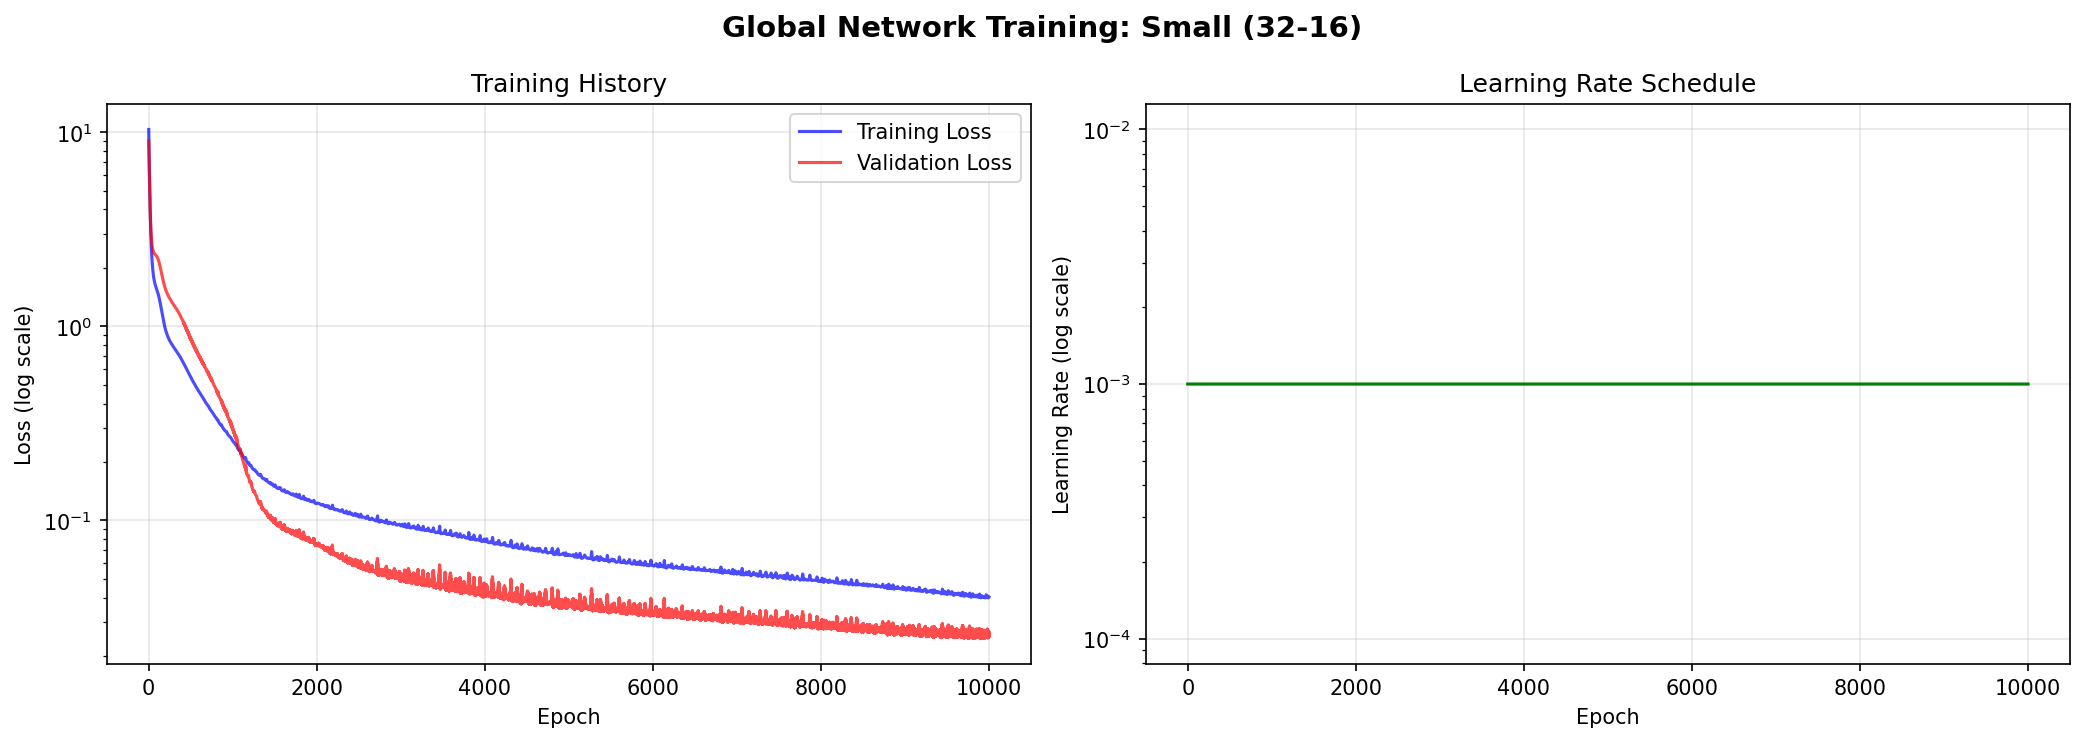

✓ Saved: step6_training_history.png


In [13]:
# ============================================================================
# VISUALIZATION 1: TRAINING HISTORY
# ============================================================================

print(f"\n{'='*80}")
print("CREATING VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss history
ax = axes[0]
ax.semilogy(losses, 'b-', alpha=0.7, label='Training Loss')
ax.semilogy(val_losses, 'r-', alpha=0.7, label='Validation Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (log scale)')
ax.set_title('Training History')
ax.legend()
ax.grid(True, alpha=0.3)

# Learning rate
ax = axes[1]
ax.semilogy(learning_rates, 'g-')
ax.set_xlabel('Epoch')
ax.set_ylabel('Learning Rate (log scale)')
ax.set_title('Learning Rate Schedule')
ax.grid(True, alpha=0.3)

plt.suptitle(f'Global Network Training: {NETWORK_CONFIGS[NETWORK_SIZE]["name"]}', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step6_training_history.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step6_training_history.png")
plt.close()

In [ ]:
# ============================================================================
# VISUALIZATION 2: SPATIAL TEST BY LOCATION
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# R² by location
ax = axes[0]
x_locs_plot = [x/H_CUBE for x in x_test]
R2_by_loc = []
for x_loc in x_test:
    results_at_x = [r for r in spatial_results if r['x'] == x_loc]
    R2_by_loc.append(np.mean([r['R2'] for r in results_at_x]))

bars = ax.bar(range(len(x_test)), R2_by_loc, color='steelblue', alpha=0.7, edgecolor='black')
ax.set_xticks(range(len(x_test)))
ax.set_xticklabels([f'x/H={x:.1f}' for x in x_locs_plot], rotation=45)
ax.set_ylabel('R²')
ax.set_title('Spatial Test R² by Location')
ax.axhline(0, color='red', linestyle='--', alpha=0.5)
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
for bar, val in zip(bars, R2_by_loc):
    ax.text(bar.get_x() + bar.get_width()/2, max(val, 0) + 0.02, f'{val:.2f}', 
            ha='center', va='bottom', fontsize=10)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# RMSE by location
ax = axes[1]
RMSE_by_loc = []
for x_loc in x_test:
    results_at_x = [r for r in spatial_results if r['x'] == x_loc]
    RMSE_by_loc.append(np.mean([r['RMSE'] for r in results_at_x]))

bars = ax.bar(range(len(x_test)), RMSE_by_loc, color='coral', alpha=0.7, edgecolor='black')
ax.set_xticks(range(len(x_test)))
ax.set_xticklabels([f'x/H={x:.1f}' for x in x_locs_plot], rotation=45)
ax.set_ylabel('RMSE [m/s]')
ax.set_title('Spatial Test RMSE by Location')
for bar, val in zip(bars, RMSE_by_loc):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', 
            ha='center', va='bottom', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle(f'Global Network Spatial Interpolation\nOverall R²={overall_spatial_R2:.3f}, RMSE={overall_spatial_RMSE:.3f}',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step6_spatial_test.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step6_spatial_test.png")
plt.close()

In [ ]:
# ============================================================================
# VISUALIZATION 3: PROFILE PREDICTIONS VS CFD
# ============================================================================

# Select two cases for visualization
test_case_ids = [list(all_cases_data.keys())[0], list(all_cases_data.keys())[4]]

fig, axes = plt.subplots(2, len(x_test), figsize=(5*len(x_test), 12))

for row, case_id in enumerate(test_case_ids):
    case_data = all_cases_data[case_id]
    params = case_parameters[case_id]
    
    for col, x_loc in enumerate(x_test):
        ax = axes[row, col] if len(x_test) > 1 else axes[row]
        
        if x_loc in case_data['profiles']:
            profile = case_data['profiles'][x_loc]
            z_cfd = profile['z']
            U_cfd = profile['U_x']
            
            # Predict
            U_pred = []
            for z_val in z_cfd:
                x_norm = x_loc / H_CUBE
                z_norm = z_val / H_CUBE
                profile_onehot = onehot_encoder.transform([[params['profile_type']]])[0]
                features = np.concatenate([[x_norm, z_norm, params['U_ref']], profile_onehot])
                features_scaled = feature_scaler.transform(features.reshape(1, -1))
                
                with torch.no_grad():
                    pred = model(torch.tensor(features_scaled, dtype=torch.float32)).item()
                U_pred.append(pred)
            
            # Plot
            ax.plot(U_cfd, z_cfd/H_CUBE, 'ko', markersize=3, alpha=0.5, label='CFD')
            ax.plot(U_pred, z_cfd/H_CUBE, 'r-', linewidth=2, label='Global NN')
            
            # Metrics
            R2 = r2_score(U_cfd, U_pred)
            RMSE = np.sqrt(mean_squared_error(U_cfd, U_pred))
            
            ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
            ax.set_xlabel('U_x [m/s]')
            ax.set_ylabel('z / H_cube [-]')
            ax.set_title(f'{case_data["profile_name"]}, x/H={x_loc/H_CUBE:.1f}\nR²={R2:.3f}, RMSE={RMSE:.3f}')
            ax.legend(loc='best', fontsize=8)
            ax.grid(True, alpha=0.3)

plt.suptitle('Global Network: Profile Predictions vs CFD (Test Locations)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step6_profile_predictions.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step6_profile_predictions.png")
plt.close()


In [ ]:
# ============================================================================
# VISUALIZATION 4: FULL 2D VELOCITY FIELD
# ============================================================================

print("\nGenerating 2D velocity field prediction...")

# Create grid
x_grid = np.linspace(0, 0.32, 200)
z_grid = np.linspace(0, 0.05, 100)
X_grid, Z_grid = np.meshgrid(x_grid, z_grid)

# Select one case for 2D visualization
case_id_2d = list(all_cases_data.keys())[0]
params_2d = case_parameters[case_id_2d]

# Predict on grid
U_grid = np.zeros_like(X_grid)
for i in range(X_grid.shape[0]):
    for j in range(X_grid.shape[1]):
        x_norm = X_grid[i, j] / H_CUBE
        z_norm = Z_grid[i, j] / H_CUBE
        profile_onehot = onehot_encoder.transform([[params_2d['profile_type']]])[0]
        features = np.concatenate([[x_norm, z_norm, params_2d['U_ref']], profile_onehot])
        features_scaled = feature_scaler.transform(features.reshape(1, -1))
        
        with torch.no_grad():
            U_grid[i, j] = model(torch.tensor(features_scaled, dtype=torch.float32)).item()

fig, ax = plt.subplots(figsize=(16, 6))

# Plot velocity field
im = ax.pcolormesh(X_grid/H_CUBE, Z_grid/H_CUBE, U_grid, cmap='RdBu_r', shading='auto')
plt.colorbar(im, ax=ax, label='U_x [m/s]')

# Draw cube
cube_rect = Rectangle((X_CUBE_FRONT/H_CUBE, 0), 1.0, 1.0,
                       linewidth=3, edgecolor='black', facecolor='gray', alpha=0.8)
ax.add_patch(cube_rect)

# Mark training and test locations
for x in x_train:
    ax.axvline(x/H_CUBE, color='green', alpha=0.2, linewidth=1)
for x in x_test:
    ax.axvline(x/H_CUBE, color='orange', alpha=0.5, linewidth=2, linestyle='--')

ax.set_xlabel('x / H_cube [-]', fontsize=12)
ax.set_ylabel('z / H_cube [-]', fontsize=12)
ax.set_title(f'2D Velocity Field Prediction: {all_cases_data[case_id_2d]["profile_name"]}\n'
             f'Green: Training locations, Orange dashed: Test locations', fontsize=14)
ax.set_xlim([0, 22])
ax.set_ylim([0, 3.5])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step6_velocity_field.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step6_velocity_field.png")
plt.close()


In [ ]:
# ============================================================================
# SAVE RESULTS
# ============================================================================

print(f"\n{'='*80}")
print("SAVING RESULTS")
print("="*80)

results = {
    'model_state': model.state_dict(),
    'model_config': {
        'n_inputs': N_FEATURES,
        'hidden_sizes': hidden_sizes,
        'activation': 'tanh',
        'n_params': n_params
    },
    'feature_scaler': feature_scaler,
    'onehot_encoder': onehot_encoder,
    'x_train': x_train,
    'x_test': x_test,
    'training_history': {
        'losses': losses,
        'val_losses': val_losses,
        'learning_rates': learning_rates,
        'epochs': len(losses)
    },
    'training_metrics': {
        'R2': train_R2,
        'RMSE': train_RMSE,
        'MAE': train_MAE
    },
    'test_metrics': {
        'R2': overall_spatial_R2,
        'RMSE': overall_spatial_RMSE,
        'MAE': overall_spatial_MAE
    },
    'spatial_results': spatial_results,
    'H_CUBE': H_CUBE,
    'FEATURE_NAMES': FEATURE_NAMES,
}

with open(RESULTS_OUTPUT, 'wb') as f:
    pickle.dump(results, f)

print(f"✓ Saved: {RESULTS_OUTPUT}")


In [ ]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

print(f"\n{'='*80}")
print("STEP 4 COMPLETE - GLOBAL MODEL SUMMARY")
print("="*80)

print(f"""
🎯 GLOBAL NEURAL NETWORK:

CONFIGURATION:
  • Architecture: {N_FEATURES} → {' → '.join(map(str, hidden_sizes))} → 1
  • Parameters: {n_params}
  • Training epochs: {len(losses)}
  • Features: {FEATURE_NAMES}

TRAINING PERFORMANCE:
  • R²:   {train_R2:.4f}
  • RMSE: {train_RMSE:.4f} m/s
  • MAE:  {train_MAE:.4f} m/s

SPATIAL TEST PERFORMANCE:
  • R²:   {overall_spatial_R2:.4f}
  • RMSE: {overall_spatial_RMSE:.4f} m/s
  • MAE:  {overall_spatial_MAE:.4f} m/s

FILES CREATED:
  ✓ step4_1_training_history.png
  ✓ step4_2_spatial_test.png
  ✓ step4_3_profile_predictions.png
  ✓ step4_4_velocity_field.png
  ✓ step4_global_results.pkl

COMPARISON READY:
  • Same train/test split as Local and LoLiMoT
  • Same metrics (R², RMSE, MAE)
  • Same visualization format
  • Ready for direct comparison!
""")

print("="*80)
print("✓ GLOBAL MODEL COMPLETE")
print("="*80)
